In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# 07 · How much can the intervals be trusted?

Two questions a reviewer would ask about notebook 03.

1. **Are the confidence intervals right?** They are cluster-robust by
   zone, which relies on having many clusters of similar size. There are
   60 zones, 38 of them in the CBD, and the regressions weight them by
   trips, so a few busy zones carry much of the weight. A **wild cluster
   restricted bootstrap** (WCR, with Webb's six-point weights) gives
   p-values and intervals that do not lean on that approximation.
2. **What if the trend bent?** The main estimate assumes the CBD's
   relative decline would have carried on in a straight line. **HonestDiD**
   (Rambachan and Roth 2023) replaces "carried on exactly" with "changed
   its slope by at most M per year" and reports the confidence interval
   for every M. The question becomes: how big a bend would it take to hide
   a real drop, or to manufacture one?

Both methods are implemented in `src/congestion/inference.py` and tested
against brute-force refits and the R package's own bias formula
(`tests/test_inference.py`).

In [2]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from congestion.did import event_study, fit_did
from congestion.inference import flci_breakdown, flci_sd, wild_bootstrap_did
from congestion.panel import FIRST_POST_WEEK, WINDOW_START, YEAR1_END, load_zone_day, window, zone_week_panel
from congestion.plots import COLORS, save, style, write_metrics
from congestion.zones import zone_group

style()
N_BOOT = int(os.environ.get("CONGESTION_N_BOOT", 9999))
pooled = zone_week_panel(load_zone_day(), ("yellow", "hvfhv"))
MAIN = pooled[pooled["pu_zone"].map(zone_group).isin(["cbd", "manhattan_north"])]
print(MAIN["pu_zone"].nunique(), "zones;", MAIN.loc[MAIN["treated"], "pu_zone"].nunique(), "in the CBD")

60 zones; 38 in the CBD


## 1. Wild cluster bootstrap

The same regressions as notebook 03 (zone and week fixed effects,
weighted by pre-toll trips, clustered by zone). For each, the analytic
95% interval next to the bootstrap one, which inverts the bootstrap test
(9,999 draws, the same draws for every candidate value). The two-step
estimate is left out: its first step (fitting each zone's trend) is
treated as known by both methods, so neither would be honest about it.

In [3]:
Y2023, Y2024, Y2025 = ("2023-01-09", "2023-12-24"), ("2024-01-08", "2024-12-22"), ("2025-01-06", "2025-12-21")


def two_years(a, b):
    w = window(MAIN, a[0], b[1], b[0])
    return w[(w["week"] <= a[1]) | (w["week"] >= b[0])]


y2_win = window(MAIN, WINDOW_START, MAIN["week"].max(), "2026-01-05")
SPECS = {
    "quick: 2025 vs 2024": (two_years(Y2024, Y2025), False),
    "quick placebo: 2024 vs 2023 (no toll)": (two_years(Y2023, Y2024), False),
    "main: trend-adjusted, year 1": (window(MAIN, WINDOW_START, YEAR1_END), True),
    "trend-adjusted, year 2 (Jan-Aug 2026)": (y2_win[(y2_win["week"] < FIRST_POST_WEEK) | (y2_win["week"] >= "2026-01-05")], True),
    "trend-adjusted placebo, 2024": (window(MAIN, "2022-07-04", Y2024[1], Y2024[0]), True),
}
boot_rows = []
for i, (label, (panel, trends)) in enumerate(SPECS.items()):
    r = fit_did(panel, weights="pre_mean_trips", unit_trends=trends)
    b = wild_bootstrap_did(panel, weights="pre_mean_trips", unit_trends=trends, n_boot=N_BOOT, seed=i)
    boot_rows.append({"specification": label, "effect": r.pct, "analytic_low": r.pct_ci[0], "analytic_high": r.pct_ci[1],
                      "p_analytic": r.p_value, "boot_low": b["pct_ci_boot"][0], "boot_high": b["pct_ci_boot"][1],
                      "p_boot": b["p_boot"]})
boot = pd.DataFrame(boot_rows)
boot["widening"] = (boot["boot_high"] - boot["boot_low"]) / (boot["analytic_high"] - boot["analytic_low"]) - 1
boot.style.format({c: "{:+.1%}" for c in ["effect", "analytic_low", "analytic_high", "boot_low", "boot_high", "widening"]}
                  | {"p_analytic": "{:.3f}", "p_boot": "{:.3f}"})

,specification,effect,analytic_low,analytic_high,p_analytic,boot_low,boot_high,p_boot,widening
0,quick: 2025 vs 2024,-2.6%,-4.0%,-1.2%,0.000,-4.1%,-1.1%,0.002,+6.0%
1,quick placebo: 2024 vs 2023 (no toll),-4.4%,-5.3%,-3.5%,0.000,-5.3%,-3.4%,0.000,+4.5%
2,"main: trend-adjusted, year 1",+1.0%,-0.3%,+2.3%,0.118,-0.3%,+2.3%,0.136,+4.8%
3,"trend-adjusted, year 2 (Jan-Aug 2026)",-3.6%,-6.0%,-1.1%,0.005,-6.1%,-1.0%,0.007,+3.3%
4,"trend-adjusted placebo, 2024",+2.0%,+0.9%,+3.1%,0.000,+0.8%,+3.2%,0.001,+5.5%


The bootstrap barely moves anything: 60 clusters, 38 of them treated, is
enough for the usual approximation here. Each conclusion of notebook 03
keeps the same sign and significance. That rules out one worry and leaves
the bigger one, which no standard error can address: the design.

## 2. HonestDiD: what if the CBD's trend bent?

### The event study it starts from

HonestDiD works on an event study's coefficients and their covariance.
The quarterly event study in notebook 03 has a strong seasonal pattern
in the gap (the CBD's share peaks every summer), which a smoothness
restriction would mistake for bends in the trend. So the bins here are
whole toll years, 52 weeks each from the toll's start: 2023, 2024 (the
reference year) and 2025. For year 2 the toll year is incomplete
(January to August 2026), so a second event study keeps only the same 34
weeks of every year, January to late August, to compare like with like.

In [4]:
es_panel = window(MAIN, WINDOW_START, MAIN["week"].max())
week_in_year = ((es_panel["week"] - FIRST_POST_WEEK).dt.days // 7) % 52
N_MATCHED = int(week_in_year[es_panel["week"] >= "2026-01-05"].max()) + 1
es_full, V1, bins1 = event_study(es_panel[es_panel["week"] <= YEAR1_END], weights="pre_mean_trips",
                                 policy_week=FIRST_POST_WEEK, bin_weeks=52, return_vcov=True)
es_matched, V2, bins2 = event_study(es_panel[week_in_year < N_MATCHED], weights="pre_mean_trips",
                                    policy_week=FIRST_POST_WEEK, bin_weeks=52, return_vcov=True)
for name, es in (("whole toll years", es_full), (f"first {N_MATCHED} weeks of each year", es_matched)):
    print(name)
    print(es[["bin", "start_week", "pct", "pct_ci_low", "pct_ci_high"]].assign(
        start_week=lambda d: d["start_week"].dt.date).to_string(index=False))
    print()

whole toll years
 bin start_week       pct  pct_ci_low  pct_ci_high
  -2 2023-01-09  0.043713    0.034262     0.053250
  -1 2024-01-08  0.000000    0.000000     0.000000
   0 2025-01-06 -0.027464   -0.041457    -0.013268

first 34 weeks of each year
 bin start_week       pct  pct_ci_low  pct_ci_high
  -2 2023-01-09  0.048359    0.036316     0.060541
  -1 2024-01-08  0.000000    0.000000     0.000000
   0 2025-01-06 -0.026375   -0.040442    -0.012102
   1 2026-01-05 -0.095883   -0.116789    -0.074482



Before the toll the gap fell by about 4-5 log points a year (2023 to
2024). After it, the 2025 gap fell by less, and 2026 by more. Under
"the trend carries on exactly" (M = 0) that is the trend-adjusted DiD of
notebook 03 in another form.

### Letting the trend bend

Under Rambachan and Roth's smoothness restriction Delta^SD(M), the gap's
slope may change by up to M log points from one year to the next. M is
easiest to read against the pre-toll slope itself: M equal to the whole
slope allows the CBD's relative decline to stop entirely, or to double,
within a year. The intervals are the fixed-length intervals the R package
uses by default for this restriction.

In [5]:
def coefs(es, bins):
    """Coefficients without the reference bin, in bin order, and the number of pre bins."""
    return es.set_index("bin").loc[bins, "beta"].to_numpy(), sum(x < 0 for x in bins)


b1, npre1 = coefs(es_full, bins1)
b2, npre2 = coefs(es_matched, bins2)
slope_full = float(-es_full.set_index("bin").loc[-2, "beta"])       # change in the gap, 2023 -> 2024
slope_matched = float(-es_matched.set_index("bin").loc[-2, "beta"])
TARGETS = {
    "year 1 (2025)": (b1, V1, npre1, np.array([1.0]), abs(slope_full)),
    "year 2 (Jan-Aug 2026)": (b2, V2, npre2, np.array([0.0, 1.0]), abs(slope_matched)),
}
SHARES = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5]
rows = []
for name, (b, V, npre, lvec, slope) in TARGETS.items():
    for k in SHARES:
        r = flci_sd(b, V, npre, lvec, k * slope)
        rows.append({"target": name, "bend_as_share_of_pre_slope": k, "M": r["M"], "estimate": np.expm1(r["estimate"]),
                     "low": np.expm1(r["lb"]), "high": np.expm1(r["ub"])})
honest = pd.DataFrame(rows)
print(f"pre-toll slope of the gap: {slope_full:+.4f} log points a year (whole years), "
      f"{slope_matched:+.4f} (Jan-Aug)")
honest.style.format({"estimate": "{:+.1%}", "low": "{:+.1%}", "high": "{:+.1%}", "M": "{:.4f}",
                     "bend_as_share_of_pre_slope": "{:.0%}"})

pre-toll slope of the gap: -0.0428 log points a year (whole years), -0.0472 (Jan-Aug)


,target,bend_as_share_of_pre_slope,M,estimate,low,high
0,year 1 (2025),0%,0.0000,+1.5%,+0.3%,+2.7%
1,year 1 (2025),25%,0.0107,+1.5%,-0.6%,+3.6%
2,year 1 (2025),50%,0.0214,+1.5%,-1.6%,+4.8%
3,year 1 (2025),75%,0.0321,+1.5%,-2.7%,+5.9%
4,year 1 (2025),100%,0.0428,+1.5%,-3.7%,+7.0%
5,year 1 (2025),150%,0.0642,+1.5%,-5.8%,+9.3%
6,year 2 (Jan-Aug 2026),0%,0.0000,-0.6%,-2.8%,+1.6%
7,year 2 (Jan-Aug 2026),25%,0.0118,-0.6%,-5.9%,+4.9%
8,year 2 (Jan-Aug 2026),50%,0.0236,-0.6%,-9.1%,+8.7%
9,year 2 (Jan-Aug 2026),75%,0.0354,-0.6%,-12.3%,+12.6%


### How big a bend would change the answer?

Two break-down points, each the smallest M (as a share of the pre-toll
slope) at which the interval stops excluding something:

* **Year 1:** zero, and a drop of 5% or more, the size an early study
  found for Uber/Lyft trips over the first 14 weeks (−5.95%).
* **Year 2:** zero, i.e. how robust the second-year decline is.

In [6]:
LOG_MINUS5 = float(np.log(0.95))
r1_m0 = flci_sd(b1, V1, npre1, np.array([1.0]), 0.0)
bd1 = flci_breakdown(b1, V1, npre1, np.array([1.0]), LOG_MINUS5, side="below", M_max=0.5)
bd1_zero = flci_breakdown(b1, V1, npre1, np.array([1.0]), 0.0,
                          side="below" if r1_m0["lb"] > 0 else "above", M_max=0.5)
r2_m0 = flci_sd(b2, V2, npre2, np.array([0.0, 1.0]), 0.0)
bd2 = flci_breakdown(b2, V2, npre2, np.array([0.0, 1.0]), 0.0,
                     side="above" if r2_m0["ub"] < 0 else "below", M_max=0.5)
breakdown = {"year1_rule_out_minus5pct": {"M": bd1, "share_of_pre_slope": bd1 / abs(slope_full)},
             "year1_exclude_zero": {"M": bd1_zero, "share_of_pre_slope": bd1_zero / abs(slope_full)},
             "year2_exclude_zero": {"M": bd2, "share_of_pre_slope": bd2 / abs(slope_matched)}}
for k, v in breakdown.items():
    print(f"{k}: M = {v['M']:.4f} log points a year, {v['share_of_pre_slope']:.0%} of the pre-toll slope")

year1_rule_out_minus5pct: M = 0.0561 log points a year, 131% of the pre-toll slope
year1_exclude_zero: M = 0.0047 log points a year, 11% of the pre-toll slope
year2_exclude_zero: M = 0.0000 log points a year, 0% of the pre-toll slope


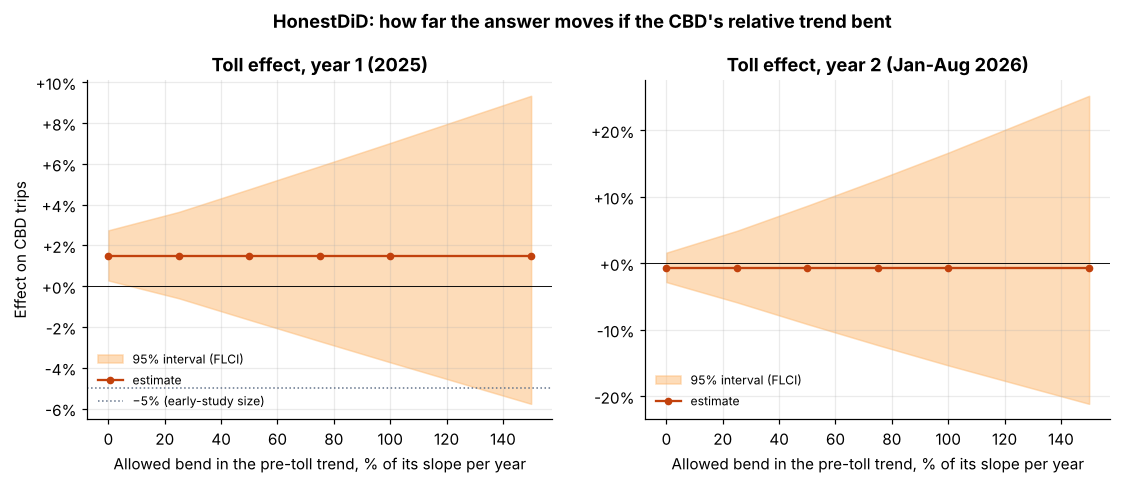

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, (name, grp) in zip(axes, honest.groupby("target", sort=False)):
    x = grp["bend_as_share_of_pre_slope"] * 100
    ax.fill_between(x, grp["low"], grp["high"], color=COLORS["band"], alpha=0.5, label="95% interval (FLCI)")
    ax.plot(x, grp["estimate"], "o-", color=COLORS["cbd"], ms=4, label="estimate")
    ax.axhline(0, color="black", lw=0.6)
    if name.startswith("year 1"):
        ax.axhline(np.expm1(LOG_MINUS5), color="#64748B", ls=":", lw=1, label="−5% (early-study size)")
    ax.set_title(f"Toll effect, {name}")
    ax.set_xlabel("Allowed bend in the pre-toll trend, % of its slope per year")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_ylabel("Effect on CBD trips")
fig.suptitle("HonestDiD: how far the answer moves if the CBD's relative trend bent", fontweight="bold", y=1.04)
save(fig, "07_honestdid.png")
plt.show()

In [8]:
def r6(x):
    return round(float(x), 6)


write_metrics("robust_inference", {
    "wild_bootstrap": {"n_boot": N_BOOT, "weights": "webb", "clusters": int(MAIN["pu_zone"].nunique()),
                       "rows": [{k: (r6(v) if isinstance(v, float) else v) for k, v in row.items()}
                                for row in boot.to_dict(orient="records")]},
    "honestdid": {
        "restriction": "Delta^SD(M), fixed-length confidence intervals",
        "bins": "52-week toll years; year 2 uses the first %d weeks of every year" % N_MATCHED,
        "pre_slope_log_points_per_year": {"whole_years": r6(slope_full), "jan_aug": r6(slope_matched)},
        "event_study_whole_years": {int(b): r6(p) for b, p in zip(es_full["bin"], es_full["pct"])},
        "event_study_jan_aug": {int(b): r6(p) for b, p in zip(es_matched["bin"], es_matched["pct"])},
        "intervals": [{k: (r6(v) if isinstance(v, (float, np.floating)) else v) for k, v in row.items()}
                      for row in honest.to_dict(orient="records")],
        "breakdown": {k: {kk: r6(vv) for kk, vv in v.items()} for k, v in breakdown.items()},
    },
})

Saved reports/metrics/robust_inference.json


## What this changes

Rendered from the numbers above; the README and decision memo quote them
and CI checks that they match.

In [9]:
main = boot.set_index("specification").loc["main: trend-adjusted, year 1"]
y1 = honest[honest["target"] == "year 1 (2025)"].set_index("bend_as_share_of_pre_slope")
y2 = honest[honest["target"] == "year 2 (Jan-Aug 2026)"].set_index("bend_as_share_of_pre_slope")
y2_nb03 = boot.set_index("specification").loc["trend-adjusted, year 2 (Jan-Aug 2026)"]
lines = [
    f"Standard errors: the wild cluster bootstrap widens the intervals by at most {boot['widening'].max():.0%} and "
    f"changes no conclusion. Main estimate: {main['effect']:+.1%}, bootstrap interval "
    f"{main['boot_low']:+.1%} to {main['boot_high']:+.1%} (p = {main['p_boot']:.2f}).",
    f"Year 1, if the CBD's pre-toll trend had carried on exactly (M = 0): {y1.loc[0.0, 'estimate']:+.1%} "
    f"({y1.loc[0.0, 'low']:+.1%} to {y1.loc[0.0, 'high']:+.1%}). Allowing the trend to bend by "
    f"{breakdown['year1_exclude_zero']['share_of_pre_slope']:.0%} of its pre-toll slope is enough for the interval to "
    "include zero, so there is no robust evidence of an increase either.",
    f"A toll-driven drop of 5% or more stays ruled out unless the CBD's relative decline sped up, in the toll year "
    f"itself and for reasons other than the toll, by more than {breakdown['year1_rule_out_minus5pct']['share_of_pre_slope']:.0%} "
    "of its pre-toll pace.",
    f"Year 2: notebook 03's trend-adjusted estimate is {y2_nb03['effect']:+.1%}. Extrapolating the pre-toll years alone "
    f"puts 2026 on trend ({y2.loc[0.0, 'estimate']:+.1%}, {y2.loc[0.0, 'low']:+.1%} to {y2.loc[0.0, 'high']:+.1%}), "
    f"and a bend of a quarter of the slope widens that to {y2.loc[0.25, 'low']:+.1%} to {y2.loc[0.25, 'high']:+.1%}. "
    "The second-year decline depends on how the trend is drawn: a pattern to watch, not a finding.",
]
print("\n\n".join(f"{i}. {t}" for i, t in enumerate(lines, 1)))

1. Standard errors: the wild cluster bootstrap widens the intervals by at most 6% and changes no conclusion. Main estimate: +1.0%, bootstrap interval -0.3% to +2.3% (p = 0.14).

2. Year 1, if the CBD's pre-toll trend had carried on exactly (M = 0): +1.5% (+0.3% to +2.7%). Allowing the trend to bend by 11% of its pre-toll slope is enough for the interval to include zero, so there is no robust evidence of an increase either.

3. A toll-driven drop of 5% or more stays ruled out unless the CBD's relative decline sped up, in the toll year itself and for reasons other than the toll, by more than 131% of its pre-toll pace.

4. Year 2: notebook 03's trend-adjusted estimate is -3.6%. Extrapolating the pre-toll years alone puts 2026 on trend (-0.6%, -2.8% to +1.6%), and a bend of a quarter of the slope widens that to -5.9% to +4.9%. The second-year decline depends on how the trend is drawn: a pattern to watch, not a finding.
